# VAT invoice reconciliation using GDT and MISA exports

This notebook reconciles VAT input and VAT output invoices exported from GDT with the corresponding MISA VAT return schedules. The review covers invoice counts, invoice status, matching invoice details, and differences in net amounts, invoice totals and VAT amounts.

Run the cells in order: select the reporting period and source files, review the source data, then reconcile the records and export the results. Input and output invoices are reviewed separately throughout.

MISA's schedules do not include invoice series. Duplicate matching keys therefore require separate review. The purchase schedule records deductible input VAT, which may differ from the VAT shown on an invoice. Agreement between the records does not, by itself, establish eligibility for an input VAT credit.




In [1]:
# Purpose: import the analysis libraries, locate this project on any computer,
# and load the reusable invoice-reading, status-review and reconciliation functions.
# This setup cell does not download files or change any source records.
from pathlib import Path
import sys
import importlib
import pandas as pd
from IPython.display import display, Markdown, HTML
from IPython import get_ipython

# Render charts inline so their images are saved inside this notebook.
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")

# Find the project folder without a computer-specific absolute path.
roots = [Path.cwd(), *Path.cwd().parents]
PROJECT_DIR = next((p for root in roots
                    for p in (root, root / "5. Portfolio" / "VAT reconciliation")
                    if (p / "vat_reconciliation.py").is_file()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Open this notebook inside the VAT reconciliation project.")
sys.path.insert(0, str(PROJECT_DIR))
import vat_reconciliation as vr
_ = importlib.reload(vr)

import matplotlib.pyplot as plt

def section_header(title):
    display(Markdown(f"### {title}"))

def show_table(frame):
    """Display amounts with commas and zeros as dashes, without changing the data."""
    styled = frame.style.hide(axis="index").format(vr.format_table_value, na_rep="-")
    left_columns = [c for c in frame.columns if c in ("Category", "Invoice Type", "")]
    if left_columns:
        styled = styled.set_properties(subset=left_columns, **{"text-align": "left"})
        styled = styled.set_table_styles([{"selector": f"th.col_heading.col{frame.columns.get_loc(c)}", "props": [("text-align", "left")]} for c in left_columns])
    display(styled)


## Reporting period and source configuration

Set `MONTH`, the taxpayer's tax code in `TAX_ID`, and the MISA workbook in `MISA_FILE` before running the remaining cells. Use source files for the same reporting period.

With `GDT_DIR = None`, the notebook selects the latest complete GDT export for the reporting month and taxpayer. If no complete export is available, it checks `data/gdt/<month>/` in the project folder. To select a different source folder, enter its path in `GDT_DIR`.

The sales export may be `sales_all_<month>.xlsx`, covering both sales invoice types, or the legacy `sales_electronic_<month>.xlsx`, covering electronic invoices only. Check the coverage shown in the source file table before interpreting any differences.


In [2]:
MONTH = "2026-08"
TAX_ID = "9900000027"
GDT_DIR = Path(".")  # Masked GDT files in the original Excel layouts.
MISA_FILE = PROJECT_DIR / "MISA_VAT_Return_Schedules.xlsx"
AMOUNT_TOLERANCE = 1  # VND; maximum difference allowed in the invoice-total and VAT comparisons.

source_dir = vr.discover_gdt(PROJECT_DIR, MONTH, TAX_ID) if GDT_DIR is None else PROJECT_DIR / Path(GDT_DIR)
print("Period:", MONTH)
print("GDT folder:", source_dir)
print("MISA workbook:", MISA_FILE)

REPORT_DIR = PROJECT_DIR / "reports" / MONTH
REPORT_DIR.mkdir(parents=True, exist_ok=True)
SHOW_OUT_OF_MONTH_DETAILS = True  # Review prior-period documents separately from invoice totals.


Period: 2026-08
GDT folder: .
MISA workbook: .\MISA_VAT_Return_Schedules.xlsx


## GDT source data and invoice status review

Check the source file status and record counts before reviewing the invoice details. The purchase data combines e-invoices with tax authority verification codes, e-invoices without those codes, and cash register e-invoices. VAT output invoices are loaded separately. Current and legacy export filenames are supported.

The status summary shows input and output invoices by category. Adjustment and replacement categories include the related original invoices. Refer to the detailed status to distinguish an adjustment invoice from an adjusted invoice, and a replacement invoice from a replaced invoice.


In [3]:
gdt, source_diagnostics = vr.load_gdt_folder(source_dir, MONTH, TAX_ID)
source_table = source_diagnostics.rename(columns={"category": "Category", "file": "File Path", "status": "Status", "rows": "Rows", "detail": "Detail"}).copy()
source_table["Status"] = source_table["Status"].str.title()
source_table["Category"] = source_table["Category"].replace({"purchases_coded": "Coded VAT Input Invoices", "purchases_no_code": "Uncoded VAT Input Invoices", "purchases_cash_register": "Cash-Register VAT Input Invoices", "sales": "VAT Output Invoices"})
show_table(source_table)
if source_diagnostics["status"].eq("blocked").any():
    print("WARNING: Required sources are missing or invalid. Counts cover loaded records only.")
# Keep the three GDT input sources available separately, then concatenate them.
purchases_coded = gdt.loc[gdt["gdt_category"].eq("purchases_coded")].copy()
purchases_no_code = gdt.loc[gdt["gdt_category"].eq("purchases_no_code")].copy()
purchases_cash_register = gdt.loc[gdt["gdt_category"].eq("purchases_cash_register")].copy()
input_invoices = pd.concat([purchases_coded, purchases_no_code, purchases_cash_register], ignore_index=True)
output_invoices = gdt.loc[gdt["direction"].eq("sales")].copy()
# Explicit source aliases and compatibility names used by the sections below.
input_invoices_gdt = purchases_gdt = input_invoices
output_invoices_gdt = sales_gdt = output_invoices
gdt_status_table = pd.DataFrame({"Category": list(vr.STATUS_LABELS.values())})
for direction, name in (("purchases", "Input VAT Invoices"), ("sales", "Output VAT Invoices")):
    counts, details = vr.status_summary(gdt.loc[gdt.direction.eq(direction)])
    gdt_status_table[name] = counts["count"].to_numpy()
    if details["overlapping_labels"].any():
        print(f"WARNING: Overlapping {name} status labels require review.")
gdt_status_table.loc[len(gdt_status_table)] = {
    "Category": "Total",
    "Input VAT Invoices": int(gdt_status_table["Input VAT Invoices"].sum()),
    "Output VAT Invoices": int(gdt_status_table["Output VAT Invoices"].sum()),
}
show_table(gdt_status_table)
for direction, label in (("purchases", "Input VAT Invoices"), ("sales", "Output VAT Invoices")):
    section_header(label)
    _, details = vr.status_summary(gdt.loc[gdt.direction.eq(direction)])
    for category in ("replacement_related", "adjustment_related", "cancelled", "other"):
        subset = details.loc[details.status_category.eq(category)]
        if category in ("replacement_related", "adjustment_related") or not subset.empty:
            display(Markdown(f"**{vr.STATUS_LABELS[category]}**"))
            if subset.empty:
                print("No records.")
            else:
                show_table(vr.display_records(subset))


Category,File Path,Status,Rows,Detail
Coded VAT Input Invoices,.\Purchases_coded_2026-08.xlsx,Loaded,389,
Uncoded VAT Input Invoices,.\Purchases_no_code_2026-08.xlsx,Loaded,378,
Cash-Register VAT Input Invoices,.\Purchases_cash_register_2026-08.xlsx,Loaded,72,
VAT Output Invoices,.\Sales_electronic_2026-08.xlsx,Loaded,189,Electronic sales only


Category,Input VAT Invoices,Output VAT Invoices
New Invoices,833,176
Adjustment Invoices,-,6
Replacement Invoices,6,7
Cancelled Invoices,-,-
Other,-,-
Total,839,189


### Input VAT Invoices

**Replacement Invoices**

Invoice Type,Seller's Tax Code,Invoice Number,Invoice Series,Issue Date,Amount Excluding VAT,VAT Amount,Invoice Total,Source Status,Import Document,File Path,Source Sheet,Source Row
Input VAT Invoices,9900000016,600046,D26T019,27/08/2026,"1,949,022","194,902","2,143,924",Replaced Invoice,False,.\Purchases_no_code_2026-08.xlsx,sheet 1,275
Input VAT Invoices,9900000016,1600046,D26T019,27/08/2026,"2,566,042","256,604","2,822,646",Replaced Invoice,False,.\Purchases_no_code_2026-08.xlsx,sheet 1,276
Input VAT Invoices,9900000016,2600046,D26T019,27/08/2026,"2,744,663","274,466","3,019,129",Replaced Invoice,False,.\Purchases_no_code_2026-08.xlsx,sheet 1,277
Input VAT Invoices,9900000016,3600046,D26T019,27/08/2026,"2,482,899","248,290","2,731,189",Replaced Invoice,False,.\Purchases_no_code_2026-08.xlsx,sheet 1,278
Input VAT Invoices,9900000016,4600046,D26T019,27/08/2026,"1,926,350","192,635","2,118,985",Replaced Invoice,False,.\Purchases_no_code_2026-08.xlsx,sheet 1,279
Input VAT Invoices,9900000016,5600046,D26T019,27/08/2026,"2,707,631","270,763","2,978,394",Replaced Invoice,False,.\Purchases_no_code_2026-08.xlsx,sheet 1,280


...

### Output VAT Invoices

**Replacement Invoices**

Invoice Type,Purchaser's Tax Code,Invoice Number,Invoice Series,Issue Date,Amount Excluding VAT,VAT Amount,Invoice Total,Source Status,Import Document,File Path,Source Sheet,Source Row
Output VAT Invoices,9900000020,600152,D26T010,11/08/2026,"2,215,980,548","221,598,055","2,437,578,603",Replacement Invoice,False,.\Sales_electronic_2026-08.xlsx,sheet 1,13
Output VAT Invoices,9900000020,1600152,D26T010,11/08/2026,"1,870,362,288","187,036,229","2,057,398,517",Replacement Invoice,False,.\Sales_electronic_2026-08.xlsx,sheet 1,14
Output VAT Invoices,9900000020,2600152,D26T010,11/08/2026,"1,924,865,041","192,486,505","2,117,351,546",Replacement Invoice,False,.\Sales_electronic_2026-08.xlsx,sheet 1,15
Output VAT Invoices,9900000020,3600152,D26T010,11/08/2026,"1,991,512,669","199,151,267","2,190,663,936",Replacement Invoice,False,.\Sales_electronic_2026-08.xlsx,sheet 1,16
Output VAT Invoices,9900000020,4600152,D26T010,11/08/2026,"1,838,630,696","183,863,070","2,022,493,766",Replacement Invoice,False,.\Sales_electronic_2026-08.xlsx,sheet 1,17
Output VAT Invoices,9900000020,5600152,D26T010,11/08/2026,"1,990,866,217","199,086,622","2,189,952,839",Replacement Invoice,False,.\Sales_electronic_2026-08.xlsx,sheet 1,18
Output VAT Invoices,9900000020,6600152,D26T010,11/08/2026,"2,235,651,419","223,565,142","2,459,216,561",Replacement Invoice,False,.\Sales_electronic_2026-08.xlsx,sheet 1,19


**Adjustment Invoices**

Invoice Type,Purchaser's Tax Code,Invoice Number,Invoice Series,Issue Date,Amount Excluding VAT,VAT Amount,Invoice Total,Source Status,Import Document,File Path,Source Sheet,Source Row
Output VAT Invoices,9900000020,600156,D26T010,21/08/2026,"6,241,184","499,295","6,740,479",Adjusted Invoice,False,.\Sales_electronic_2026-08.xlsx,sheet 1,59
Output VAT Invoices,9900000020,1600156,D26T010,21/08/2026,"9,416,378","753,310","10,169,688",Adjusted Invoice,False,.\Sales_electronic_2026-08.xlsx,sheet 1,60
Output VAT Invoices,9900000020,2600156,D26T010,21/08/2026,"9,838,147","787,052","10,625,199",Adjusted Invoice,False,.\Sales_electronic_2026-08.xlsx,sheet 1,61
Output VAT Invoices,9900000020,3600156,D26T010,21/08/2026,"7,178,378","574,270","7,752,648",Adjusted Invoice,False,.\Sales_electronic_2026-08.xlsx,sheet 1,62
Output VAT Invoices,9900000020,4600156,D26T010,21/08/2026,"7,096,345","567,708","7,664,053",Adjusted Invoice,False,.\Sales_electronic_2026-08.xlsx,sheet 1,63
Output VAT Invoices,9900000020,5600156,D26T010,21/08/2026,"10,900,252","872,020","11,772,272",Adjusted Invoice,False,.\Sales_electronic_2026-08.xlsx,sheet 1,64


## MISA accounting and VAT return schedules

Review the purchase and sales schedules for the selected reporting period. The input total includes customs declarations, which are identified separately from VAT input invoices in the breakdown below. Supporting details and invoices issued outside the GDT search month are shown in the next section.

After running the source cells, use these DataFrames to inspect the complete records:

```python
input_invoices         # All three GDT purchase categories combined
output_invoices        # GDT VAT output invoices
input_invoices_misa    # MISA VAT input invoices and customs declarations
output_invoices_misa   # MISA VAT output invoices
```

Use `.head()` for a quick preview or `show_table(vr.display_records(input_invoices))` for a formatted table. Numeric zeros are displayed as `-`; the underlying values remain unchanged.


In [4]:
misa = vr.read_misa(MISA_FILE, MONTH, customs_as_new=True)
input_invoices_misa = misa.loc[misa.direction.eq("purchases")].copy()
output_invoices_misa = misa.loc[misa.direction.eq("sales")].copy()
misa_totals = pd.DataFrame({"": ["Input VAT Invoices", "Output VAT Invoices"],
                            "Total Invoices": [int(misa.direction.eq("purchases").sum()), int(misa.direction.eq("sales").sum())]})
show_table(misa_totals)
section_header(f"Total Input VAT Invoices: {len(input_invoices_misa):,}")
section_header(f"Total Output VAT Invoices: {len(output_invoices_misa):,}")
input_records = misa.loc[misa.direction.eq("purchases")]
cd_count = int(input_records.import_document.sum())
print(f"Input VAT Invoices breakdown: {len(input_records) - cd_count:,} VAT Invoices and {cd_count:,} Customs Declarations (CDs).")


,Total Invoices
Input VAT Invoices,774
Output VAT Invoices,182


### Total Input VAT Invoices: 774

### Total Output VAT Invoices: 182

Input VAT Invoices breakdown: 754 VAT Invoices and 20 Customs Declarations (CDs).


## MISA document details for review

**Invoice status:** Review the sales notes in Column I for adjustment, replacement or cancellation details. Blank sales notes are classified as New Invoices. Purchase notes in Column M record special cases and are not treated as invoice-status evidence. For this status summary, ordinary purchase records and customs declarations are grouped under New Invoices; customs declarations remain separately identified in the input breakdown.

**Customs declarations:** In the MISA input review table, 12-digit document numbers carry the review reason **Custom Declaration**. Column K identifies import documents with an X, and Column L provides additional details. Document numbers and dates are taken from Columns B and C. These records remain in the MISA schedule and are presented separately from domestic VAT input invoices.

**Invoices issued outside the search month:** A VAT return schedule may include invoices issued in another month. These records remain in MISA's totals and are checked against the available GDT data. If no matching GDT record is found, they appear in MISA Only. Set `SHOW_OUT_OF_MONTH_DETAILS` to show or hide their detail tables without changing the reconciliation.


In [5]:
for direction, label in (("sales", "Output VAT Invoices"), ("purchases", "Input VAT Invoices")):
    section_header(label)
    records = misa.loc[misa.direction.eq(direction)]
    if direction == "sales":
        _, details = vr.status_summary(records)
        for category in ("replacement_related", "adjustment_related", "cancelled", "other"):
            subset = details.loc[details.status_category.eq(category)]
            if not subset.empty:
                display(Markdown(f"**{vr.STATUS_LABELS[category]} (Column I)**"))
                show_table(vr.display_records(subset))
    else:
        customs_documents = records.loc[records.import_document].copy()
        if not customs_documents.empty:
            display(Markdown("**Customs Declaration Details — Columns K / L**"))
            customs_view = vr.display_records(customs_documents)
            show_table(customs_view)
        special_purchase_notes = records.loc[records.notes.fillna("").ne("")]
        if not special_purchase_notes.empty:
            display(Markdown("**Purchase Special-Case Notes (Column M)**"))
            show_table(vr.display_records(special_purchase_notes))
    outside_issue_month = records.loc[records.issue_date.dt.strftime("%Y-%m").ne(MONTH)]
    if SHOW_OUT_OF_MONTH_DETAILS and not outside_issue_month.empty:
        display(Markdown("**Documents Issued Outside the GDT Search Month Included in This MISA Declaration**"))
        show_table(vr.display_records(outside_issue_month))


### Output VAT Invoices

**Adjustment Invoices (Column I)**

Invoice Type,Purchaser's Tax Code,Invoice Number,Invoice Series,Issue Date,Amount Excluding VAT,VAT Amount,Invoice Total,Source Status,MISA Notes,Import Document,Import Marker (Column K),Import Detail (Column L),File Path,Source Sheet,Source Row
Output VAT Invoices,9900000020,00600156,,21/08/2026,"6,241,184","499,295","6,740,479",Adjusted Invoice,Adjusted Invoice,False,,,.\MISA_VAT_Return_Schedules.xlsx,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ HÀNG",61
Output VAT Invoices,9900000020,01600156,,21/08/2026,"9,416,378","753,310","10,169,688",Adjusted Invoice,Adjusted Invoice,False,,,.\MISA_VAT_Return_Schedules.xlsx,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ HÀNG",62
Output VAT Invoices,9900000020,02600156,,21/08/2026,"9,838,147","787,052","10,625,199",Adjusted Invoice,Adjusted Invoice,False,,,.\MISA_VAT_Return_Schedules.xlsx,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ HÀNG",63
Output VAT Invoices,9900000020,03600156,,21/08/2026,"7,178,378","574,270","7,752,648",Adjusted Invoice,Adjusted Invoice,False,,,.\MISA_VAT_Return_Schedules.xlsx,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ HÀNG",64
Output VAT Invoices,9900000020,04600156,,21/08/2026,"7,096,345","567,708","7,664,053",Adjusted Invoice,Adjusted Invoice,False,,,.\MISA_VAT_Return_Schedules.xlsx,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ HÀNG",65
Output VAT Invoices,9900000020,05600156,,21/08/2026,"10,900,252","872,020","11,772,272",Adjusted Invoice,Adjusted Invoice,False,,,.\MISA_VAT_Return_Schedules.xlsx,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ HÀNG",66


### Input VAT Invoices

**Customs Declaration Details — Columns K / L**

Invoice Type,Seller's Tax Code,Invoice Number,Invoice Series,Issue Date,Amount Excluding VAT,VAT Amount,Invoice Total,Source Status,MISA Notes,Import Document,Import Marker (Column K),Import Detail (Column L),File Path,Source Sheet,Source Row
Input VAT Invoices,,980000000001,,05/08/2026,"229,746,579","22,974,658","252,721,237",New Invoice,,True,X,,.\MISA_VAT_Return_Schedules.xlsx,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ CỦA H",76
Input VAT Invoices,,980001000001,,05/08/2026,"180,701,178","18,070,118","198,771,296",New Invoice,,True,X,,.\MISA_VAT_Return_Schedules.xlsx,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ CỦA H",77
Input VAT Invoices,,980002000001,,05/08/2026,"226,545,251","22,654,525","249,199,776",New Invoice,,True,X,,.\MISA_VAT_Return_Schedules.xlsx,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ CỦA H",78
Input VAT Invoices,,980003000001,,05/08/2026,"268,944,738","26,894,474","295,839,212",New Invoice,,True,X,,.\MISA_VAT_Return_Schedules.xlsx,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ CỦA H",79
Input VAT Invoices,,980004000001,,05/08/2026,"207,841,124","20,784,112","228,625,236",New Invoice,,True,X,,.\MISA_VAT_Return_Schedules.xlsx,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ CỦA H",80
Input VAT Invoices,,980005000001,,05/08/2026,"250,163,856","25,016,385","275,180,241",New Invoice,,True,X,,.\MISA_VAT_Return_Schedules.xlsx,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ CỦA H",81
Input VAT Invoices,,980006000001,,05/08/2026,"274,598,132","27,459,813","302,057,945",New Invoice,,True,X,,.\MISA_VAT_Return_Schedules.xlsx,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ CỦA H",82
Input VAT Invoices,,980000000002,,07/08/2026,"768,516,276","61,481,302","829,997,578",New Invoice,,True,X,,.\MISA_VAT_Return_Schedules.xlsx,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ CỦA H",150
Input VAT Invoices,,980001000002,,07/08/2026,"533,312,498","42,665,000","575,977,498",New Invoice,,True,X,,.\MISA_VAT_Return_Schedules.xlsx,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ CỦA H",151
Input VAT Invoices,,980002000002,,07/08/2026,"691,583,614","55,326,689","746,910,303",New Invoice,,True,X,,.\MISA_VAT_Return_Schedules.xlsx,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ CỦA H",152


**Documents Issued Outside the GDT Search Month Included in This MISA Declaration**

Invoice Type,Seller's Tax Code,Invoice Number,Invoice Series,Issue Date,Amount Excluding VAT,VAT Amount,Invoice Total,Source Status,MISA Notes,Import Document,Import Marker (Column K),Import Detail (Column L),File Path,Source Sheet,Source Row
Input VAT Invoices,9900000016,600049,,29/07/2026,"417,554","41,755","459,309",New Invoice,,False,,,.\MISA_VAT_Return_Schedules.xlsx,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ CỦA H",7
Input VAT Invoices,9900000016,1600049,,29/07/2026,"528,422","52,842","581,264",New Invoice,,False,,,.\MISA_VAT_Return_Schedules.xlsx,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ CỦA H",8
Input VAT Invoices,9900000016,2600049,,29/07/2026,"473,164","47,316","520,480",New Invoice,,False,,,.\MISA_VAT_Return_Schedules.xlsx,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ CỦA H",9
Input VAT Invoices,9900000016,3600049,,29/07/2026,"420,529","42,053","462,582",New Invoice,,False,,,.\MISA_VAT_Return_Schedules.xlsx,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ CỦA H",10
Input VAT Invoices,9900000016,4600049,,29/07/2026,"526,404","52,640","579,044",New Invoice,,False,,,.\MISA_VAT_Return_Schedules.xlsx,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ CỦA H",11
Input VAT Invoices,9900000016,5600049,,29/07/2026,"380,499","38,050","418,549",New Invoice,,False,,,.\MISA_VAT_Return_Schedules.xlsx,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ CỦA H",12


## Invoice totals and status comparison

Compare the GDT and MISA record counts and invoice-status categories for inputs and outputs separately. The MISA input total includes customs declarations, as shown in the breakdown. Review any records classified as Other to establish their status.


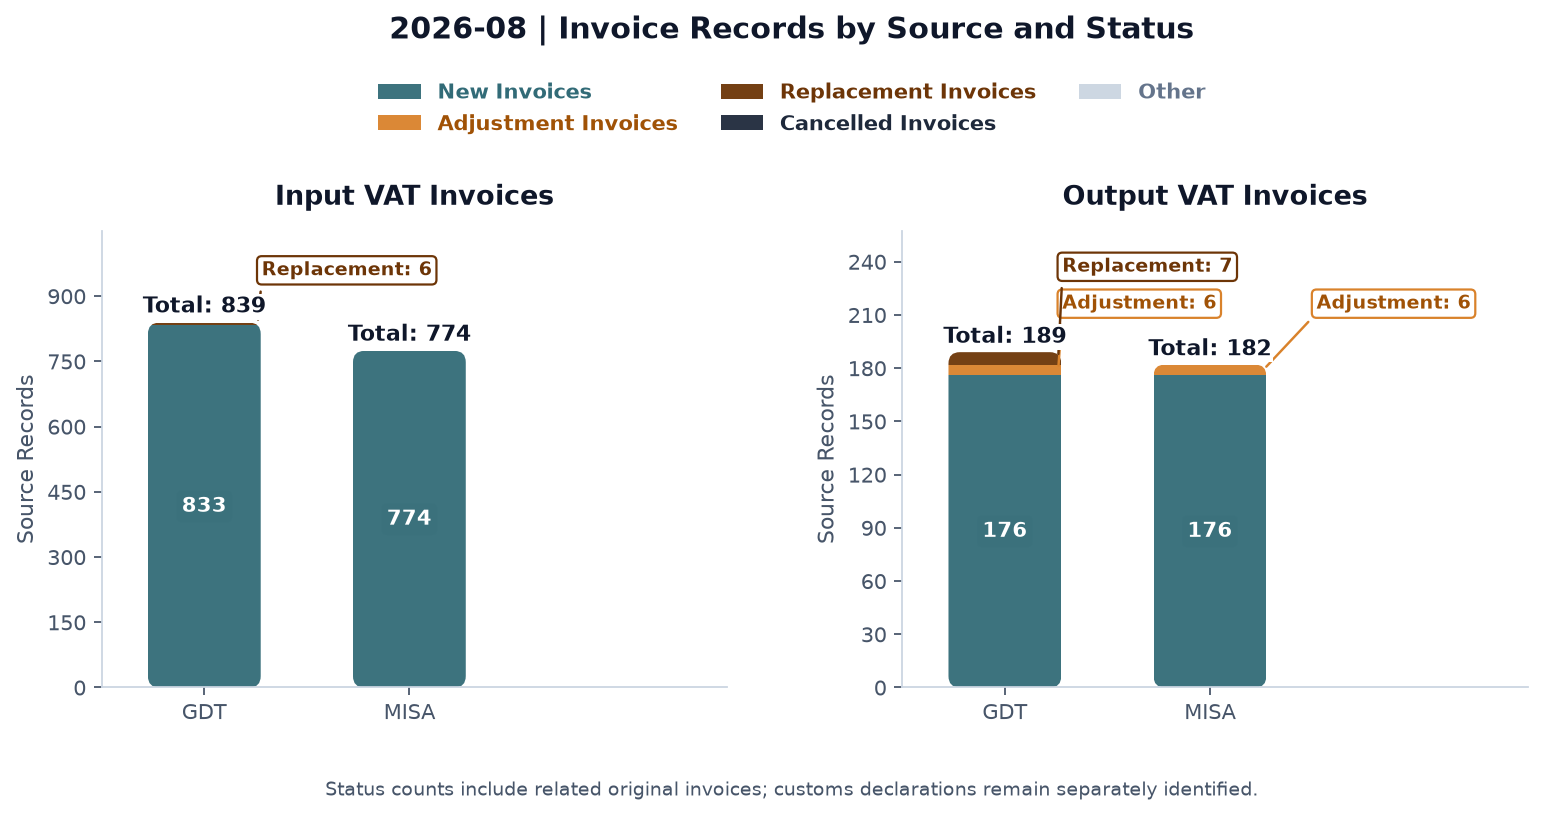

### Input VAT Invoices

Source,Invoice Type,Total Invoices,New Invoices,Adjustment Invoices,Replacement Invoices,Cancelled Invoices,Other
GDT,Input VAT Invoices,839,833,-,6,-,-
MISA,Input VAT Invoices,774,774,-,-,-,-


### Output VAT Invoices

Source,Invoice Type,Total Invoices,New Invoices,Adjustment Invoices,Replacement Invoices,Cancelled Invoices,Other
GDT,Output VAT Invoices,189,176,6,7,-,-
MISA,Output VAT Invoices,182,176,6,-,-,-


In [6]:
invoice_overview = vr.source_status_overview(gdt, misa)
if source_diagnostics.status.eq("loaded").all():
    status_figure = vr.plot_comparison(invoice_overview, MONTH)
    vr.save_chart(status_figure, REPORT_DIR / "Invoice_status_comparison.png")
    plt.show()
else:
    print("Chart withheld until all required source files are loaded.")
for label in ("Input VAT Invoices", "Output VAT Invoices"):
    section_header(label)
    show_table(invoice_overview.loc[invoice_overview["Invoice Type"].eq(label)])


## Reconciliation and items for review

**Matching key**

- Input invoices: invoice number + issue date + seller's tax code.
- Output invoices: invoice number + issue date + purchaser's tax code.

Numeric leading zeros are disregarded only when matching the records. Original identifiers remain in the source datasets, and dates are compared as calendar dates. Duplicate matching keys require separate review to avoid linking an invoice to several records.

**Amount comparison**

| Check | GDT | MISA |
|---|---|---|
| Input net amount | Value excluding VAT | Purchase value excluding VAT |
| Input invoice total | Invoice total, including VAT | Purchase value excluding VAT + deductible input VAT |
| Input VAT | VAT amount on the invoice | Deductible input VAT |
| Output net amount | Value excluding VAT | Sales revenue excluding VAT |
| Output invoice total | Invoice total, including VAT | Sales revenue excluding VAT + output VAT |
| Output VAT | VAT amount on the invoice | Output VAT |

The GDT invoice total is taken directly from the export. Blank GDT invoice totals and VAT amounts are treated as zero for comparison, while original blanks are retained in the source data. Missing MISA amounts require review. Net amount, invoice total and VAT must all match within `AMOUNT_TOLERANCE` for the records to be reported as reconciled. Blank GDT net amounts remain missing and carry the review reason **Commercial Invoices**. This is a review classification for this project; nonblank net-amount differences are also reported for investigation.

Adjustment, replacement and cancelled invoices use the same matching key. Review their status details and any amount differences before making accounting adjustments.


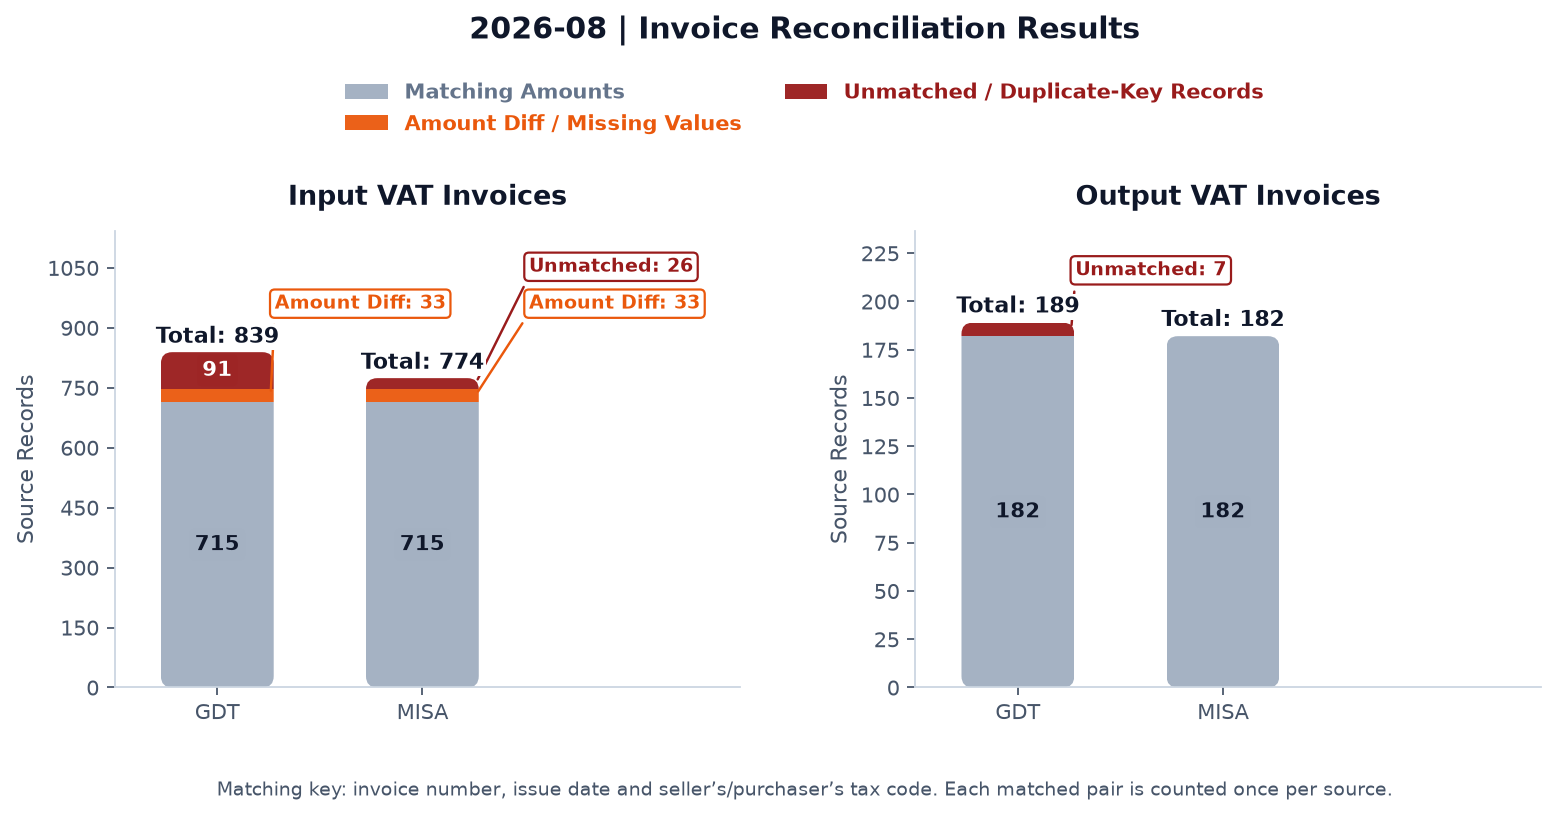

### Input VAT Invoices

Source,Invoice Type,Total Invoices,Invoices Matched by Key,Matched Invoices,Amount Differences / Missing Values,Unmatched / Duplicate-Key Records,Records Requiring Review
GDT,Input VAT Invoices,839,748,715,33,91,124
MISA,Input VAT Invoices,774,748,715,33,26,59


Input VAT Invoices: 748 invoices match on invoice number, issue date and seller's tax code.
Of these, 715 also match on net amount, invoice total and VAT.
Input VAT Invoices — GDT Records Requiring Review (124)


Review Reason,Seller's Tax Code,Invoice Number,Invoice Series,Issue Date,GDT Amount Excluding VAT,MISA Amount Excluding VAT,Net Amount Difference (MISA − GDT),GDT Invoice Total,MISA Invoice Total,Invoice Total Difference (MISA − GDT),GDT VAT Amount,MISA VAT Amount,VAT Difference (MISA − GDT),Invoice Status / Notes,Source Sheet,Source Row
GDT Only,9900000001,1600004,D26T027,10/08/2026,"508,208",-,-,"559,028",-,-,"50,820",-,-,New Invoice,sheet 1,109
GDT Only,9900000001,1600005,D26T027,10/08/2026,"3,389,058",-,-,"3,727,963",-,-,"338,905",-,-,New Invoice,sheet 1,116
GDT Only,9900000001,1600006,D26T027,10/08/2026,"530,400",-,-,"583,440",-,-,"53,040",-,-,New Invoice,sheet 1,123
GDT Only,9900000001,1600007,D26T027,10/08/2026,"459,243",-,-,"505,167",-,-,"45,924",-,-,New Invoice,sheet 1,130
GDT Only,9900000001,1600008,D26T027,10/08/2026,"448,586",-,-,"493,444",-,-,"44,858",-,-,New Invoice,sheet 1,137
GDT Only,9900000001,1600009,D26T027,10/08/2026,"3,308,589",-,-,"3,639,447",-,-,"330,858",-,-,New Invoice,sheet 1,144
GDT Only,9900000001,2600004,D26T027,10/08/2026,"319,805",-,-,"351,785",-,-,"31,980",-,-,New Invoice,sheet 1,110
GDT Only,9900000001,2600005,D26T027,10/08/2026,"2,447,633",-,-,"2,692,396",-,-,"244,763",-,-,New Invoice,sheet 1,117
GDT Only,9900000001,2600006,D26T027,10/08/2026,"509,246",-,-,"560,170",-,-,"50,924",-,-,New Invoice,sheet 1,124
GDT Only,9900000001,2600007,D26T027,10/08/2026,"477,806",-,-,"525,586",-,-,"47,780",-,-,New Invoice,sheet 1,131


Input VAT Invoices — MISA Records Requiring Review (59)


Review Reason,Seller's Tax Code,Invoice Number,Invoice Series,Issue Date,GDT Amount Excluding VAT,MISA Amount Excluding VAT,Net Amount Difference (MISA − GDT),GDT Invoice Total,MISA Invoice Total,Invoice Total Difference (MISA − GDT),GDT VAT Amount,MISA VAT Amount,VAT Difference (MISA − GDT),Invoice Status / Notes,Source Sheet,Source Row
Custom Declaration,,980000000001,,05/08/2026,-,"229,746,579",-,-,"252,721,237",-,-,"22,974,658",-,New Invoice,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ CỦA H",76
Custom Declaration,,980001000001,,05/08/2026,-,"180,701,178",-,-,"198,771,296",-,-,"18,070,118",-,New Invoice,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ CỦA H",77
Custom Declaration,,980002000001,,05/08/2026,-,"226,545,251",-,-,"249,199,776",-,-,"22,654,525",-,New Invoice,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ CỦA H",78
Custom Declaration,,980003000001,,05/08/2026,-,"268,944,738",-,-,"295,839,212",-,-,"26,894,474",-,New Invoice,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ CỦA H",79
Custom Declaration,,980004000001,,05/08/2026,-,"207,841,124",-,-,"228,625,236",-,-,"20,784,112",-,New Invoice,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ CỦA H",80
Custom Declaration,,980005000001,,05/08/2026,-,"250,163,856",-,-,"275,180,241",-,-,"25,016,385",-,New Invoice,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ CỦA H",81
Custom Declaration,,980006000001,,05/08/2026,-,"274,598,132",-,-,"302,057,945",-,-,"27,459,813",-,New Invoice,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ CỦA H",82
Custom Declaration,,980000000002,,07/08/2026,-,"768,516,276",-,-,"829,997,578",-,-,"61,481,302",-,New Invoice,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ CỦA H",150
Custom Declaration,,980001000002,,07/08/2026,-,"533,312,498",-,-,"575,977,498",-,-,"42,665,000",-,New Invoice,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ CỦA H",151
Custom Declaration,,980002000002,,07/08/2026,-,"691,583,614",-,-,"746,910,303",-,-,"55,326,689",-,New Invoice,"BẢNG KÊ HOÁ ĐƠN, CHỨNG TỪ CỦA H",152


### Output VAT Invoices

Source,Invoice Type,Total Invoices,Invoices Matched by Key,Matched Invoices,Amount Differences / Missing Values,Unmatched / Duplicate-Key Records,Records Requiring Review
GDT,Output VAT Invoices,189,182,182,-,7,7
MISA,Output VAT Invoices,182,182,182,-,-,-


Output VAT Invoices: 182 invoices match on invoice number, issue date and purchaser's tax code.
Of these, 182 also match on net amount, invoice total and VAT.
Output VAT Invoices — GDT Records Requiring Review (7)


Review Reason,Purchaser's Tax Code,Invoice Number,Invoice Series,Issue Date,GDT Amount Excluding VAT,MISA Amount Excluding VAT,Net Amount Difference (MISA − GDT),GDT Invoice Total,MISA Invoice Total,Invoice Total Difference (MISA − GDT),GDT VAT Amount,MISA VAT Amount,VAT Difference (MISA − GDT),Invoice Status / Notes,Source Sheet,Source Row
GDT Only,9900000020,1600152,D26T010,11/08/2026,"1,870,362,288",-,-,"2,057,398,517",-,-,"187,036,229",-,-,Replacement Invoice,sheet 1,14
GDT Only,9900000020,2600152,D26T010,11/08/2026,"1,924,865,041",-,-,"2,117,351,546",-,-,"192,486,505",-,-,Replacement Invoice,sheet 1,15
GDT Only,9900000020,3600152,D26T010,11/08/2026,"1,991,512,669",-,-,"2,190,663,936",-,-,"199,151,267",-,-,Replacement Invoice,sheet 1,16
GDT Only,9900000020,4600152,D26T010,11/08/2026,"1,838,630,696",-,-,"2,022,493,766",-,-,"183,863,070",-,-,Replacement Invoice,sheet 1,17
GDT Only,9900000020,5600152,D26T010,11/08/2026,"1,990,866,217",-,-,"2,189,952,839",-,-,"199,086,622",-,-,Replacement Invoice,sheet 1,18
GDT Only,9900000020,600152,D26T010,11/08/2026,"2,215,980,548",-,-,"2,437,578,603",-,-,"221,598,055",-,-,Replacement Invoice,sheet 1,13
GDT Only,9900000020,6600152,D26T010,11/08/2026,"2,235,651,419",-,-,"2,459,216,561",-,-,"223,565,142",-,-,Replacement Invoice,sheet 1,19


In [7]:
# Prepare both directions before displaying the chart and the review tables.
reconciliation = {}
review_tables = {}
blocked_directions = {}
for direction, label in (("purchases", "Input VAT Invoices"), ("sales", "Output VAT Invoices")):
    categories = source_diagnostics.loc[source_diagnostics.category.str.startswith("purchases") if direction == "purchases" else source_diagnostics.category.eq("sales")]
    if categories.status.ne("loaded").any():
        blocked_directions[direction] = "Reconciliation blocked: supply valid source files."
        continue
    result = vr.reconcile(gdt, misa, MONTH, direction, AMOUNT_TOLERANCE)
    reconciliation[direction] = result
    review_tables[direction] = vr.source_review_views(result)

matching_summary = vr.matching_overview(reconciliation, gdt, misa) if reconciliation else pd.DataFrame()
if len(reconciliation) == 2:
    matching_figure = vr.plot_comparison(matching_summary, MONTH, matching=True)
    vr.save_chart(matching_figure, REPORT_DIR / "Reconciliation_results.png")
    plt.show()

# Present the summary first, followed by the supporting records for each direction.
for direction, label in (("purchases", "Input VAT Invoices"), ("sales", "Output VAT Invoices")):
    section_header(label)
    if direction not in reconciliation:
        print(blocked_directions[direction])
        continue
    show_table(matching_summary.loc[matching_summary["Invoice Type"].eq(label)])
    review_exports = vr.original_header_export_tables(reconciliation[direction])
    for block in review_exports["Mismatch Reconciliations"].attrs.get("vertical_blocks", []):
        display(HTML(vr.review_block_html(block)))
    result = reconciliation[direction]
    key_pairs = int(result["result"].isin(vr.PAIRED_RESULTS).sum())
    party = "seller's" if direction == "purchases" else "purchaser's"
    print(f"{label}: {key_pairs:,} invoices match on invoice number, issue date and {party} tax code.")
    print(f"Of these, {int(result['result'].eq('matched_amounts_agree').sum()):,} also match on net amount, invoice total and VAT.")
    for source, records in review_tables[direction].items():
        if not records.empty:
            print(f"{label} — {source} Records Requiring Review ({len(records)})")
            show_table(records)
# Each matching pair appears once for each source; do not add GDT and MISA counts.


## Save input and output reconciliation workbooks

Export one input workbook and one output workbook for the configured month, each with four sheets:

- **Matching Reconciliations:** one column per equivalent field, without a Result column. Display the original identifier with leading zeros when the sources use different padding. Shared information appears once; source-specific fields retain GDT/MISA labels. If shared descriptive values differ, both are labelled within one cell rather than silently choosing one. Both sources’ File Path, Source Sheet and Source Row remain available.
- **Mismatch Reconciliations:** each review shows the GDT record above its MISA counterpart. Equivalent fields occupy the same columns, anchored to the GDT layout. Each source retains its own field labels, with blank positions where a field is unavailable. Review reasons, invoice-total and VAT differences and source references appear alongside the blocks. If there are no mismatches, the sheet states this explicitly.
- **Invoices Only From GDT:** original GDT headers/order, with cash-register-only columns appended and GDT Invoice Type added for inputs (Coded, No Code or Cash Register).
- **Invoices Only From MISA:** original MISA headers/order; merged-header spacer positions are retained, and invoice subheaders or their parent labels provide field names.

Matching requires net amount, invoice total and VAT to match within `AMOUNT_TOLERANCE`. Records with blank GDT net amounts appear in the mismatch review under Commercial Invoices, even when invoice total and VAT match. Numeric leading zeros are ignored only in temporary matching keys; full source DataFrames retain original identifiers and blanks. Unpaired customs declarations and prior-period documents appear in source-only sheets. Source statuses do not exclude a key match; ambiguous keys remain review items.

Amounts use thousands separators. Charts remain in the notebook. This step exports only the two reconciliation workbooks; historical files remain unchanged. Workbooks are written only for source-complete directions.


In [8]:
exported_workbooks = {}
for direction, label in (("purchases", "Input"), ("sales", "Output")):
    if direction in reconciliation:
        path = REPORT_DIR / f"{label}_VAT_Reconciliation_{MONTH}.xlsx"
        exported_workbooks[direction] = vr.export_reconciliation_workbook(reconciliation[direction], path)
        print(f"{label} VAT reconciliation: {path}")
if not exported_workbooks:
    print("No reconciliation was completed; check the source diagnostics above.")


Input VAT reconciliation: .\reports\2026-08\Input_VAT_Reconciliation_2026-08.xlsx


Output VAT reconciliation: .\reports\2026-08\Output_VAT_Reconciliation_2026-08.xlsx
